In [2]:
import glob
import h5py
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt
import os
import pandas as pd

In [3]:
def read_files(glob_pattern, minyear=0, maxyear=999):
    files = glob.glob(glob_pattern)
    times = []
    peaklats_n = []
    peaklats_s = []
    
    for fpath in tqdm(files):
        year = int(os.path.basename(fpath)[:4])
        if year > maxyear:
            continue
        if year < minyear:
            continue

        times.append(pd.to_datetime(os.path.basename(fpath)[:-4]))
        hdf = h5py.File(fpath)
        peaklats_n.append(hdf['peak_lat_north'][()].item())
        peaklats_s.append(hdf['peak_lat_south'][()].item())
        hdf.close()
    
    return times, np.array(peaklats_n), np.array(peaklats_s)

In [4]:
times_samples, peaklat_north_samples, peaklat_south_samples = read_files(
    '../data/validation.first_cut/peaklat_truncated/*.hdf5',
    maxyear=2017
)

100%|███████████████████████████████████████████████████████████████████████████████| 835/835 [00:00<00:00, 2060.41it/s]


In [5]:
times_testdata, peaklat_north_testdata, peaklat_south_testdata = read_files(
    '../data/validation.first_cut/peaklat_testdata/*.hdf5',
    maxyear=2017
)

100%|███████████████████████████████████████████████████████████████████████████████| 835/835 [00:00<00:00, 1986.43it/s]


Text(0.5, 0.98, 'Latitudes of Peak Magnetic Field Strength at 1 $R_\\odot$')

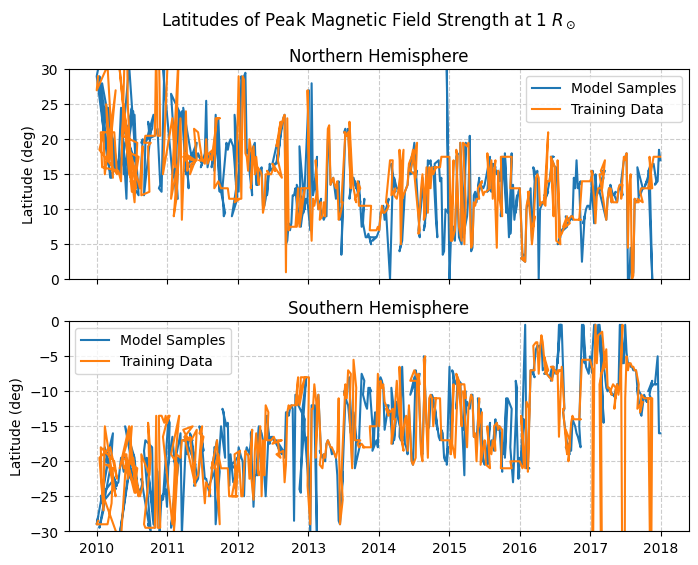

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(times_samples, peaklat_north_samples, label='Model Samples')
axes[0].plot(times_samples, peaklat_north_testdata, label='Training Data')
axes[0].set_ylim(0, 30)
axes[0].legend()
axes[0].set_ylabel('Latitude (deg)')
axes[0].grid(linestyle='dashed', color='#ccc')
axes[0].set_title('Northern Hemisphere')

axes[1].plot(times_samples, peaklat_south_samples, label='Model Samples')
axes[1].plot(times_samples, peaklat_south_testdata, label='Training Data')
axes[1].set_ylim(-30, 0)
axes[1].legend(loc='upper left')
axes[1].set_ylabel('Latitude (deg)')
axes[1].grid(linestyle='dashed', color='#ccc')
axes[1].set_title('Southern Hemisphere')


fig.suptitle(r'Latitudes of Peak Magnetic Field Strength at 1 $R_\odot$')

In [1]:
plt.figure(figsize=(12, 6))

plt.subplot(121)
bins = np.arange(0, 30, 2)
plt.hist(peaklat_north_samples, bins=bins, label='Model Samples', alpha=0.5)
plt.hist(peaklat_north_testdata, bins=bins, label='Training Data', alpha=0.5)
plt.legend()
plt.title(r'Latitude of Peak Field Strength at 1 $R_\odot$ (2010-2018)' + '\nNorthern Hemisphere')
plt.ylabel('Bin Count')
plt.grid(color='#ccc', linestyle='dashed')
plt.xlabel('Latitude (deg)')

bins = np.arange(-30, 0, 2)
plt.subplot(122)
plt.hist(peaklat_south_samples, bins=bins, label='Model Samples', alpha=0.5)
plt.hist(peaklat_south_testdata, bins=bins, label='Training Data', alpha=0.5)
plt.legend()
plt.title(r'Latitude of Peak Field Strength at 1 $R_\odot$ (2010-2018)' + '\nSouthern Hemisphere')
plt.ylabel('Bin Count')
plt.grid(color='#ccc', linestyle='dashed')
plt.xlabel('Latitude (deg)')

NameError: name 'plt' is not defined